# Financial Econometrics — Homework 1

**Simulation practice: simple OLS regression**

The population model is

$$
y_i = \beta_0 + \beta_1 x_i + \varepsilon_i, \qquad i = 1, \ldots, n,
$$

with true parameters $\beta_0 = 5$ and $\beta_1 = -2.5$. In matrix form,

$$
y = X\beta + \varepsilon, \qquad X = [\,1 \;\; x\,], \qquad
\hat\beta = (X'X)^{-1} X'y.
$$

The regressor is $x_i \sim U(0, 1)$, independent of the error $\varepsilon_i \sim N(0, V)$.

| DGP | $V$ | $n$ |
| --- | --- | --- |
| DGP1 | 0.16 | 20 |
| DGP2 | 1 | 20 |
| DGP3 | 1 | 200 |

Each design is drawn 10 times from one seeded generator. Run 1 of each design is the sample that is plotted and reported as a single regression. The ten estimates are then averaged.

Launch this notebook from the project root so figures are written to `figures/`:

```bash
uv run jupyter notebook homework1.ipynb
```


## 1. Setup

`SEED` fixes the stream of random numbers, so restarting the kernel and running every cell from the top reproduces the same samples.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

SEED = 2026
rng = np.random.default_rng(SEED)

BETA0, BETA1 = 5.0, -2.5
N_RUNS = 10
DGPS = {
    "DGP1": {"V": 0.16, "n": 20},
    "DGP2": {"V": 1.00, "n": 20},
    "DGP3": {"V": 1.00, "n": 200},
}

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
results = {}

np.set_printoptions(precision=4, suppress=True)


## 2. Draw one sample

$x$ is an $n \times 1$ vector of uniform draws. The error is an $n \times 1$ normal vector with variance $V$, and

$$
y = \beta_0 + \beta_1 x + \varepsilon.
$$


In [2]:
def simulate(n, V, generator=None):
    """Return one sample as column vectors y, x, eps, each n x 1."""
    generator = rng if generator is None else generator
    x = generator.uniform(0, 1, size=(n, 1))
    eps = generator.normal(0, np.sqrt(V), size=(n, 1))
    y = BETA0 + BETA1 * x + eps
    return y, x, eps


## 3. OLS estimator

Stack a column of ones next to $x$ and compute the normal-equation estimator

$$
\hat\beta = (X'X)^{-1} X'y.
$$


In [3]:
def ols(y, x):
    """OLS via beta_hat = (X'X)^{-1} X'y, with X = [1 x]."""
    ones = np.ones_like(x)
    X = np.hstack([ones, x])
    beta_hat = np.linalg.inv(X.T @ X) @ (X.T @ y)
    return X, beta_hat


## 4. Plot and Monte Carlo summaries

The figure for a single sample shows the scatter, the fitted line $\hat y = \hat\beta_0 + \hat\beta_1 x$, and the true line $y = 5 - 2.5x$.

The sampling variance of $\hat\beta$ shrinks with $n$ and grows with $V$. For $x \sim U(0,1)$,

$$
\mathrm{plim}\,\frac{X'X}{n}
= \begin{bmatrix} 1 & 1/2 \\ 1/2 & 1/3 \end{bmatrix},
\qquad
\left(\mathrm{plim}\,\frac{X'X}{n}\right)^{-1}
= \begin{bmatrix} 4 & -6 \\ -6 & 12 \end{bmatrix}.
$$

The asymptotic standard deviations used below are therefore

$$
\mathrm{SD}(\hat\beta_0) \approx \sqrt{4V/n}, \qquad
\mathrm{SD}(\hat\beta_1) \approx \sqrt{12V/n}.
$$

These are large-sample benchmarks. The exact finite-sample variance still depends on the realized $x$ values.


In [4]:
def theoretical_se(n, V):
    """Asymptotic SD of (beta0_hat, beta1_hat) for x ~ U(0, 1)."""
    return np.sqrt(V / n * np.array([4.0, 12.0]))


def plot_fit(name, n, V, x, y, beta_hat):
    """Scatter, OLS fit, and the true line for the first replication."""
    fig, ax = plt.subplots(figsize=(5.5, 4))
    ax.scatter(x, y, s=18, alpha=0.7, label="Simulated data")
    xs = np.linspace(0, 1, 100)
    b0, b1 = beta_hat[0, 0], beta_hat[1, 0]
    ax.plot(
        xs,
        b0 + b1 * xs,
        color="crimson",
        lw=2,
        label=rf"OLS fit: $\hat y={b0:.3f}{b1:+.3f}x$",
    )
    ax.plot(
        xs,
        BETA0 + BETA1 * xs,
        color="black",
        ls="--",
        lw=1,
        label=r"True line: $y=5-2.5x$",
    )
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"{name}: V = {V}, n = {n} (run 1)")
    ax.legend(fontsize=8)
    fig.tight_layout()
    path = FIG_DIR / f"{name.lower()}_fit.png"
    fig.savefig(path, dpi=200)
    print(f"Figure saved: {path}")
    plt.show()


def summarize(name, estimates, n, V):
    """Print the 10 estimates, their mean and SD, and the asymptotic SD."""
    mean = estimates.mean(axis=0)
    sd = estimates.std(axis=0, ddof=1)
    asy = theoretical_se(n, V)
    print(f"=== {name} (V={V}, n={n}) ===")
    print("Run   beta0_hat   beta1_hat")
    for r, (b0, b1) in enumerate(estimates, 1):
        print(f"{r:>3d}   {b0:9.4f}   {b1:9.4f}")
    print(f"Mean  {mean[0]:9.4f}   {mean[1]:9.4f}   true = ({BETA0:.1f}, {BETA1:.1f})")
    print(f"SD    {sd[0]:9.4f}   {sd[1]:9.4f}   (across the {len(estimates)} runs)")
    print(f"Asy.  {asy[0]:9.4f}   {asy[1]:9.4f}   (asymptotic SD)")
    return mean, sd, asy


def run_dgp(name, n, V, n_runs=N_RUNS, preview=5):
    """Repeat the DGP n_runs times. Plot and describe replication 1."""
    estimates = np.zeros((n_runs, 2))
    for r in range(n_runs):
        y, x, eps = simulate(n, V)
        _, beta_hat = ols(y, x)
        estimates[r] = beta_hat.ravel()
        if r == 0:
            print(f"{name}: stored y, x, eps with shapes {y.shape}, {x.shape}, {eps.shape}")
            print(f"First {preview} rows of [y, x, eps]:")
            print(np.hstack([y, x, eps])[:preview])
            print(
                f"Run 1 estimate: beta0_hat = {beta_hat[0, 0]:.4f}, "
                f"beta1_hat = {beta_hat[1, 0]:.4f}"
            )
            plot_fit(name, n, V, x, y, beta_hat)
    return estimates


## 5. DGP1 — $V = 0.16$, $n = 20$

Low noise, small sample. The scatter should sit close to the true line, and one OLS fit should already be near $(5, -2.5)$.


DGP1: stored y, x, eps with shapes (20, 1), (20, 1), (20, 1)
First 5 rows of [y, x, eps]:
[[ 4.3618  0.1789 -0.1909]
 [ 3.6629  0.6399  0.2626]
 [ 3.7389  0.4673 -0.0929]
 [ 4.0143  0.3705 -0.0595]
 [ 4.3694  0.3549  0.2567]]
Run 1 estimate: beta0_hat = 5.0865, beta1_hat = -2.5045


Figure saved: figures/dgp1_fit.png


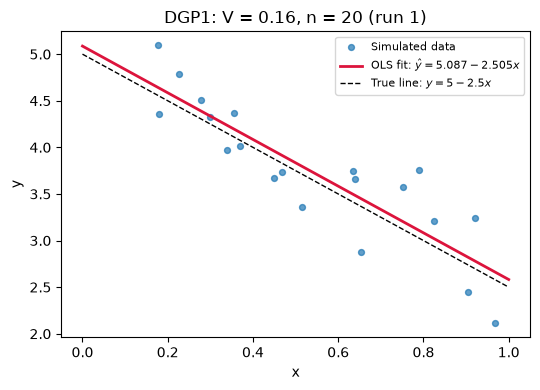

=== DGP1 (V=0.16, n=20) ===
Run   beta0_hat   beta1_hat
  1      5.0865     -2.5045
  2      4.7899     -2.2518
  3      4.9072     -2.4293
  4      4.7564     -2.1248
  5      4.9386     -2.3473
  6      4.6632     -2.1162
  7      5.1338     -2.8707
  8      4.9058     -2.0711
  9      4.6653     -2.1443
 10      4.9624     -2.2975
Mean     4.8809     -2.3158   true = (5.0, -2.5)
SD       0.1616      0.2421   (across the 10 runs)
Asy.     0.1789      0.3098   (asymptotic SD)


(array([ 4.8809, -2.3158]), array([0.1616, 0.2421]), array([0.1789, 0.3098]))

In [5]:
results["DGP1"] = run_dgp("DGP1", **DGPS["DGP1"])
summarize("DGP1", results["DGP1"], **DGPS["DGP1"])


## 6. DGP2 — $V = 1$, $n = 20$

Same sample size as DGP1, with error variance $1 / 0.16 = 6.25$ times larger. The cloud of points is wider, so a single fit can tilt away from the true line, and the ten estimates should be more dispersed.


DGP2: stored y, x, eps with shapes (20, 1), (20, 1), (20, 1)
First 5 rows of [y, x, eps]:
[[ 6.4878  0.2142  2.0232]
 [ 2.4773  0.8696 -0.3488]
 [ 4.0408  0.9065  1.3071]
 [ 2.8041  0.6893 -0.4727]
 [ 4.5057  0.3943  0.4914]]
Run 1 estimate: beta0_hat = 5.7230, beta1_hat = -2.9348
Figure saved: figures/dgp2_fit.png


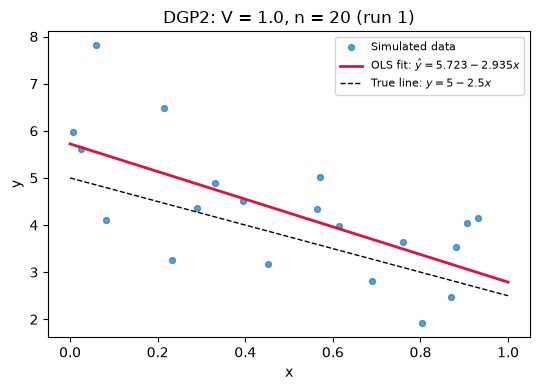

=== DGP2 (V=1.0, n=20) ===
Run   beta0_hat   beta1_hat
  1      5.7230     -2.9348
  2      4.6799     -2.2719
  3      5.0915     -2.5309
  4      5.0644     -3.1262
  5      4.9944     -3.0375
  6      5.2115     -2.8415
  7      4.8987     -2.8717
  8      4.6316     -1.7000
  9      5.6359     -3.7015
 10      5.2500     -2.8237
Mean     5.1181     -2.7840   true = (5.0, -2.5)
SD       0.3584      0.5333   (across the 10 runs)
Asy.     0.4472      0.7746   (asymptotic SD)


(array([ 5.1181, -2.784 ]), array([0.3584, 0.5333]), array([0.4472, 0.7746]))

In [6]:
results["DGP2"] = run_dgp("DGP2", **DGPS["DGP2"])
summarize("DGP2", results["DGP2"], **DGPS["DGP2"])


## 7. DGP3 — $V = 1$, $n = 200$

Same noise as DGP2, ten times as many observations. The scatter is still noisy, but the fitted line should lock onto the true line. Moving from $n = 20$ to $n = 200$ scales asymptotic standard deviations by $\sqrt{20/200} = 1/\sqrt{10} \approx 0.316$.


DGP3: stored y, x, eps with shapes (200, 1), (200, 1), (200, 1)
First 5 rows of [y, x, eps]:
[[ 4.1894  0.2365 -0.2194]
 [ 1.3612  0.7286 -1.8174]
 [ 3.2752  0.1845 -1.2635]
 [ 2.7088  0.7572 -0.3981]
 [ 7.0333  0.0508  2.1603]]
Run 1 estimate: beta0_hat = 4.8357, beta1_hat = -2.4485


Figure saved: figures/dgp3_fit.png


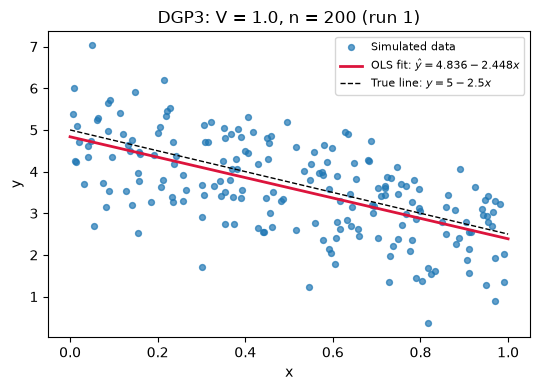

=== DGP3 (V=1.0, n=200) ===
Run   beta0_hat   beta1_hat
  1      4.8357     -2.4485
  2      4.6798     -2.1085
  3      4.7245     -2.2813
  4      5.1651     -2.8934
  5      5.0535     -2.6810
  6      4.8758     -2.3414
  7      5.0708     -2.5751
  8      5.4388     -3.1286
  9      4.7588     -2.1055
 10      5.0194     -2.3073
Mean     4.9622     -2.4871   true = (5.0, -2.5)
SD       0.2340      0.3347   (across the 10 runs)
Asy.     0.1414      0.2449   (asymptotic SD)


(array([ 4.9622, -2.4871]), array([0.234 , 0.3347]), array([0.1414, 0.2449]))

In [7]:
results["DGP3"] = run_dgp("DGP3", **DGPS["DGP3"])
summarize("DGP3", results["DGP3"], **DGPS["DGP3"])


## 8. Comparison across designs

The table collects the Monte Carlo mean and standard deviation of $\hat\beta$ next to the asymptotic benchmark.


In [8]:
header = (
    f"{'DGP':<6} {'V':>6} {'n':>5} "
    f"{'mean b0':>10} {'mean b1':>10} "
    f"{'sd b0':>8} {'sd b1':>8} "
    f"{'asy b0':>8} {'asy b1':>8}"
)
print(header)
print("-" * len(header))
for name, estimates in results.items():
    n, V = DGPS[name]["n"], DGPS[name]["V"]
    mean = estimates.mean(axis=0)
    sd = estimates.std(axis=0, ddof=1)
    asy = theoretical_se(n, V)
    print(
        f"{name:<6} {V:6.2f} {n:5d} "
        f"{mean[0]:10.4f} {mean[1]:10.4f} "
        f"{sd[0]:8.4f} {sd[1]:8.4f} "
        f"{asy[0]:8.4f} {asy[1]:8.4f}"
    )


DGP         V     n    mean b0    mean b1    sd b0    sd b1   asy b0   asy b1
-----------------------------------------------------------------------------
DGP1     0.16    20     4.8809    -2.3158   0.1616   0.2421   0.1789   0.3098
DGP2     1.00    20     5.1181    -2.7840   0.3584   0.5333   0.4472   0.7746
DGP3     1.00   200     4.9622    -2.4871   0.2340   0.3347   0.1414   0.2449


## 9. What the designs show

OLS is unbiased in this design: $x$ is independent of $\varepsilon$ and the error has mean zero, so $E[\hat\beta] = \beta$. Ten replications are a small Monte Carlo, so the averages still move around $(5, -2.5)$.

In this seeded run the averages are $(4.881, -2.316)$ for DGP1, $(5.118, -2.784)$ for DGP2, and $(4.962, -2.487)$ for DGP3. The large sample is the one that lands on the truth. The two small samples are in the right neighborhood, with gaps of a few tenths that are ordinary for $n = 20$.

**DGP1 versus DGP2** ($n$ fixed at 20, $V$ from 0.16 to 1). Raising the error variance spreads $y$ around the same line. Sampling variance of $\hat\beta$ is proportional to $V$, so the asymptotic standard deviations grow by $\sqrt{1/0.16} = 2.5$, from $(0.179, 0.310)$ to $(0.447, 0.775)$. The ten-run standard deviations rise from $(0.162, 0.242)$ to $(0.358, 0.533)$, a factor of about 2.2. Same direction as the formula; ten draws are too few for the factor to equal 2.5 exactly. The scatterplots match that story. DGP1 sits close to the true line and run 1 is $(5.087, -2.505)$. DGP2 is a wide cloud and run 1 is $(5.723, -2.935)$.

**DGP2 versus DGP3** ($V$ fixed at 1, $n$ from 20 to 200). Extra observations average the noise out. Asymptotic standard deviations fall by $\sqrt{10} \approx 3.16$, from $(0.447, 0.775)$ to $(0.141, 0.245)$. The plotted DGP3 fit is already $(4.836, -2.448)$, almost on the true line, even though the points are as noisy as in DGP2. Across the ten runs the sample standard deviations fall only from $(0.358, 0.533)$ to $(0.234, 0.335)$. The estimates do tighten, and run 1 is pinned down, but ten runs cannot recover a factor of $\sqrt{10}$. Runs 4 and 8 of DGP3 still produce slopes of $-2.89$ and $-3.13$.

The next section repeats the experiment 5000 times. That Monte Carlo is not required by the homework. It is where the asymptotic formula, and the factor $\sqrt{10}$, show up once the noise in the standard deviations is averaged away.


## 10. Supplementary check: 5000 replications

This block uses a separate generator (`seed = 1`), so rerunning it does not change the ten-run results above.


In [9]:
rng2 = np.random.default_rng(1)
N_MC = 5000
print(f"Supplementary: {N_MC} replications per DGP")
for name, p in DGPS.items():
    n, V = p["n"], p["V"]
    draws = np.zeros((N_MC, 2))
    for r in range(N_MC):
        y, x, _ = simulate(n, V, generator=rng2)
        draws[r] = ols(y, x)[1].ravel()
    asy = theoretical_se(n, V)
    print(
        f"{name}: mean = {draws.mean(0).round(4)}, "
        f"sd = {draws.std(0, ddof=1).round(4)}, "
        f"asy = {asy.round(4)}"
    )


Supplementary: 5000 replications per DGP
DGP1: mean = [ 5.0033 -2.508 ], sd = [0.1868 0.3262], asy = [0.1789 0.3098]


DGP2: mean = [ 5.0089 -2.5178], sd = [0.47   0.8079], asy = [0.4472 0.7746]


DGP3: mean = [ 5.0002 -2.4985], sd = [0.14   0.2409], asy = [0.1414 0.2449]


With 5000 replications the means sit on $(5, -2.5)$ in every design: about $(5.003, -2.508)$, $(5.009, -2.518)$, and $(5.000, -2.499)$.

The Monte Carlo standard deviations line up with $\sqrt{4V/n}$ and $\sqrt{12V/n}$:

| DGP | SD of $\hat\beta$ | Asymptotic SD |
| --- | --- | --- |
| DGP1 | $(0.187, 0.326)$ | $(0.179, 0.310)$ |
| DGP2 | $(0.470, 0.808)$ | $(0.447, 0.775)$ |
| DGP3 | $(0.140, 0.241)$ | $(0.141, 0.245)$ |

DGP2 is $2.5$ times as dispersed as DGP1, and DGP3 is about $1/\sqrt{10}$ as dispersed as DGP2. That is the variance formula, not an artifact of one unlucky sample of ten runs.